<a href="https://colab.research.google.com/github/dasha03-beep/labs/blob/main/lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа 2
## Обучение MLP в PyTorch — классификация изображений

**Цель:** научиться обучать многослойный перцептрон в PyTorch на датасете Fashion-MNIST,
сравнить оптимизаторы (SGD, SGD+momentum, Adam, AdamW) и методы регуляризации
(Dropout, BatchNorm, L2), оценить качество модели на тестовой выборке.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
import time
from copy import deepcopy

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("PyTorch:", torch.__version__)

Device: cpu
PyTorch: 2.11.0+cpu


## Шаг 1. Подготовка данных
Загружаем Fashion-MNIST (одежда, 10 классов, 28×28 grayscale).
Делим train на train/val = 90/10.

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])

train_dataset = torchvision.datasets.FashionMNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = torchvision.datasets.FashionMNIST(
    root="./data", train=False, download=True, transform=transform
)

CLASSES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("Train:", len(train_dataset))
print("Test :", len(test_dataset))
print("Shape:", train_dataset[0][0].shape)

100%|██████████| 26.4M/26.4M [00:02<00:00, 9.18MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 137kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.66MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 9.91MB/s]

Train: 60000
Test : 10000
Shape: torch.Size([1, 28, 28])


### Задание 1.1
Вывести 9 случайных изображений из train в виде сетки 3×3.
Определить визуально, какие классы легко перепутать.

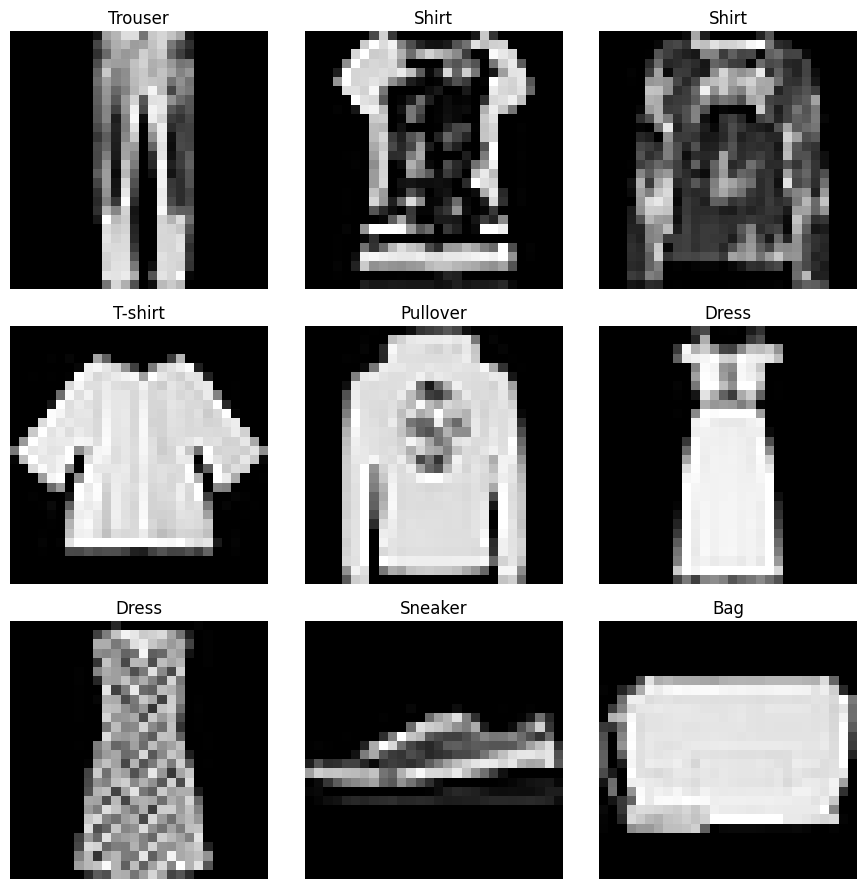

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for ax in axes.flat:
    idx = np.random.randint(len(train_dataset))
    img, label = train_dataset[idx]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(CLASSES[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

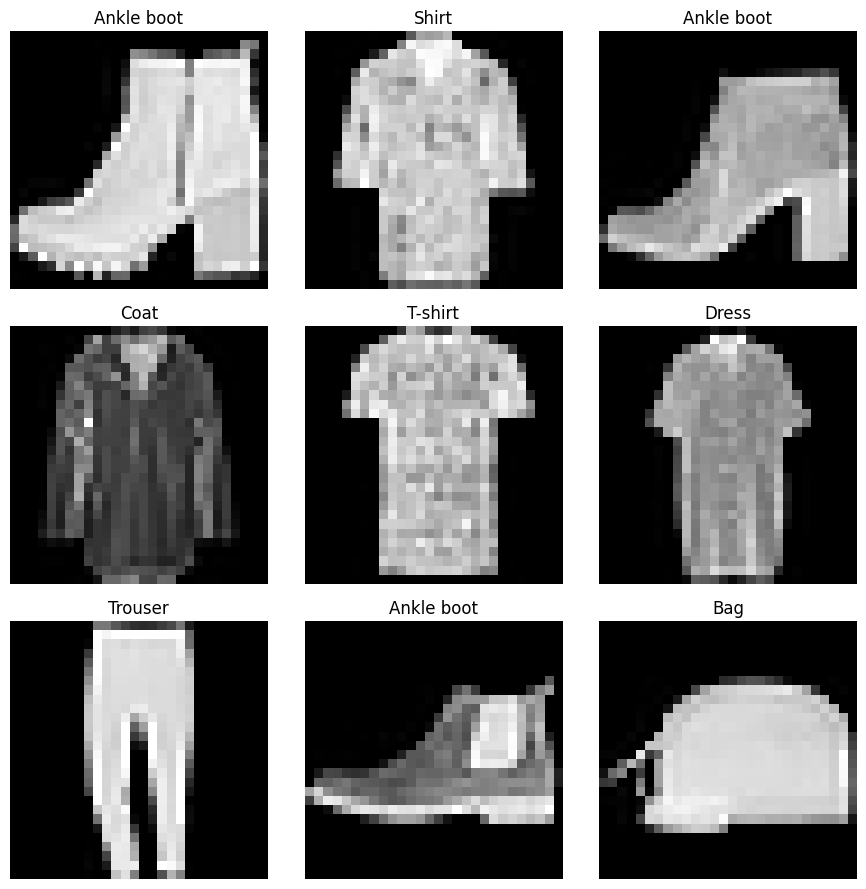

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for ax in axes.flat:
    idx = np.random.randint(len(train_dataset))
    img, label = train_dataset[idx]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(CLASSES[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

### Задание 1.2
Разделить train на train/val (90/10), создать DataLoader'ы.

In [4]:
train_size = int(0.9 * len(train_dataset))
val_size = len(train_dataset) - train_size
train_subset, val_subset = random_split(
    train_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_subset, batch_size=64,  shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_subset,   batch_size=256, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset, batch_size=256, shuffle=False, num_workers=2)

print("Train:", len(train_subset), "Val:", len(val_subset), "Test:", len(test_dataset))

Train: 54000 Val: 6000 Test: 10000


## Шаг 2. Архитектура MLP
Flatten → Linear(784→256) → [BN] → ReLU → [Dropout] → Linear(256→128) → [BN] → ReLU → [Dropout] → Linear(128→10)

In [5]:
class MLP(nn.Module):
    def __init__(self, input_size=784, hidden_sizes=(256, 128), num_classes=10,
                 dropout_rate=0.0, use_batchnorm=False):
        super().__init__()
        layers = []
        prev = input_size
        for h in hidden_sizes:
            layers.append(nn.Linear(prev, h))
            if use_batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))
            prev = h
        layers.append(nn.Linear(prev, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.net(x)

### Задание 2.1 / 2.2
Посчитать число параметров по слоям и сравнить с лаб. 1 (~13 000).

In [6]:
model = MLP().to(device)

first  = 784*256 + 256
second = 256*128 + 128
third  = 128*10 + 10
total  = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Первый слой:  {first:,}")
print(f"Второй слой:  {second:,}")
print(f"Выходной:     {third:,}")
print(f"Всего:        {total:,}")

Первый слой:  200,960
Второй слой:  32,896
Выходной:     1,290
Всего:        235,146


## Шаг 3. Функция потерь и цикл обучения
Определяем:
- train_epoch — один проход по train
- evaluate — один проход по val/test
- fit — полный цикл с early stopping
- plot_history — графики loss и accuracy

In [7]:
criterion = nn.CrossEntropyLoss()

def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(X)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * X.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        total += y.size(0)
    return running_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    preds_all, labels_all = [], []
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        loss = criterion(logits, y)
        running_loss += loss.item() * X.size(0)
        preds = logits.argmax(1)
        correct += (preds == y).sum().item()
        total += y.size(0)
        preds_all.extend(preds.cpu().numpy())
        labels_all.extend(y.cpu().numpy())
    return running_loss/total, correct/total, np.array(preds_all), np.array(labels_all)

def fit(model, train_loader, val_loader, criterion, optimizer,
        epochs=30, patience=7, device=device, verbose=True):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss = float("inf")
    best_w = deepcopy(model.state_dict())
    no_improve = 0
    for epoch in range(1, epochs+1):
        t0 = time.time()
        tr_loss, tr_acc = train_epoch(model, train_loader, criterion, optimizer, device)
        vl_loss, vl_acc, _, _ = evaluate(model, val_loader, criterion, device)
        dt = time.time() - t0
        history["train_loss"].append(tr_loss); history["val_loss"].append(vl_loss)
        history["train_acc"].append(tr_acc);   history["val_acc"].append(vl_acc)
        if vl_loss < best_val_loss:
            best_val_loss = vl_loss
            best_w = deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1
        if verbose:
            print(f"Epoch {epoch:3d} | {dt:.1f}s | "
                  f"Train {tr_loss:.4f}/{tr_acc:.4f} | Val {vl_loss:.4f}/{vl_acc:.4f}")
        if no_improve >= patience:
            print(f"Early stop на эпохе {epoch}")
            break
    model.load_state_dict(best_w)
    return history

def plot_history(history, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history["train_loss"], label="train")
    ax[0].plot(history["val_loss"], label="val")
    ax[0].set_title(f"{title} Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(history["train_acc"], label="train")
    ax[1].plot(history["val_acc"], label="val")
    ax[1].set_title(f"{title} Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

### Задание 3.1
Обучить базовую модель (без dropout/BN) на SGD(lr=0.01), 30 эпох.
Построить графики train/val loss и accuracy.

Epoch   1 | 15.4s | Train 0.9296/0.7131 | Val 0.5964/0.7857
Epoch   2 | 15.0s | Train 0.5188/0.8160 | Val 0.5031/0.8227
Epoch   3 | 14.6s | Train 0.4584/0.8371 | Val 0.4582/0.8377
Epoch   4 | 16.0s | Train 0.4253/0.8485 | Val 0.4396/0.8433
Epoch   5 | 14.6s | Train 0.4026/0.8571 | Val 0.4158/0.8512
Epoch   6 | 14.6s | Train 0.3853/0.8625 | Val 0.4203/0.8440
Epoch   7 | 14.6s | Train 0.3710/0.8674 | Val 0.3933/0.8588
Epoch   8 | 14.6s | Train 0.3583/0.8718 | Val 0.3759/0.8660
Epoch   9 | 14.7s | Train 0.3483/0.8747 | Val 0.3804/0.8673
Epoch  10 | 15.4s | Train 0.3377/0.8789 | Val 0.3584/0.8710
Epoch  11 | 15.2s | Train 0.3294/0.8822 | Val 0.3592/0.8713
Epoch  12 | 14.6s | Train 0.3197/0.8840 | Val 0.3535/0.8713
Epoch  13 | 14.7s | Train 0.3126/0.8876 | Val 0.3497/0.8740
Epoch  14 | 14.6s | Train 0.3054/0.8907 | Val 0.3376/0.8797
Epoch  15 | 14.6s | Train 0.2995/0.8920 | Val 0.3513/0.8762
Epoch  16 | 14.6s | Train 0.2924/0.8951 | Val 0.3344/0.8803
Epoch  17 | 14.6s | Train 0.2866/0.8955 

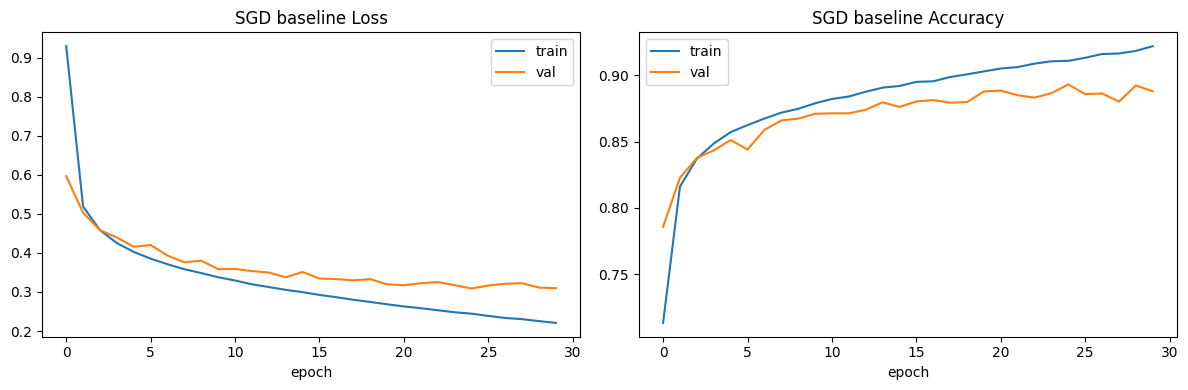

In [8]:
torch.manual_seed(42)
base_model = MLP(dropout_rate=0.0, use_batchnorm=False).to(device)
optimizer_sgd = optim.SGD(base_model.parameters(), lr=0.01)

history_sgd = fit(base_model, train_loader, val_loader, criterion, optimizer_sgd,
                  epochs=30, patience=7)
plot_history(history_sgd, "SGD baseline")

### Задание 3.3
Сравнить Cross-Entropy и MSE + Softmax.
Готовим MLPWithSoftmax и функцию обучения на MSE.

In [9]:
class MLPWithSoftmax(MLP):
    def forward(self, x):
        return torch.softmax(super().forward(x), dim=1)

def train_epoch_mse(model, loader, optimizer, device):
    model.train()
    mse = nn.MSELoss()
    running_loss, correct, total = 0.0, 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        probs = model(X)
        y_oh = torch.nn.functional.one_hot(y, 10).float()
        loss = mse(probs, y_oh)
        loss.backward(); optimizer.step()
        running_loss += loss.item() * X.size(0)
        correct += (probs.argmax(1) == y).sum().item()
        total += y.size(0)
    return running_loss/total, correct/total

def fit_mse(model, train_loader, val_loader, optimizer, epochs=15, device=device):
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(1, epochs+1):
        tr_loss, tr_acc = train_epoch_mse(model, train_loader, optimizer, device)
        model.eval()
        mse = nn.MSELoss()
        vl_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for X, y in val_loader:
                X, y = X.to(device), y.to(device)
                probs = model(X)
                y_oh = torch.nn.functional.one_hot(y, 10).float()
                vl_loss += mse(probs, y_oh).item() * X.size(0)
                correct += (probs.argmax(1) == y).sum().item()
                total += y.size(0)
        vl_loss /= total; vl_acc = correct/total
        hist["train_loss"].append(tr_loss); hist["val_loss"].append(vl_loss)
        hist["train_acc"].append(tr_acc);   hist["val_acc"].append(vl_acc)
        print(f"Epoch {epoch:2d} | Train {tr_loss:.4f}/{tr_acc:.4f} | Val {vl_loss:.4f}/{vl_acc:.4f}")
    return hist

Обучаем две модели с одинаковым seed по 15 эпох:
- CE (Cross-Entropy)
- MSE + Softmax

In [10]:
torch.manual_seed(42)
model_ce = MLP(dropout_rate=0.0, use_batchnorm=False).to(device)
opt_ce = optim.SGD(model_ce.parameters(), lr=0.01)
hist_ce = fit(model_ce, train_loader, val_loader, criterion, opt_ce,
              epochs=15, patience=15, verbose=False)
for i in range(15):
    print(f"CE  epoch {i+1:2d} | train_loss {hist_ce['train_loss'][i]:.4f} | val_acc {hist_ce['val_acc'][i]:.4f}")

CE  epoch  1 | train_loss 0.9296 | val_acc 0.7857
CE  epoch  2 | train_loss 0.5188 | val_acc 0.8227
CE  epoch  3 | train_loss 0.4584 | val_acc 0.8377
CE  epoch  4 | train_loss 0.4253 | val_acc 0.8433
CE  epoch  5 | train_loss 0.4026 | val_acc 0.8512
CE  epoch  6 | train_loss 0.3853 | val_acc 0.8440
CE  epoch  7 | train_loss 0.3710 | val_acc 0.8588
CE  epoch  8 | train_loss 0.3583 | val_acc 0.8660
CE  epoch  9 | train_loss 0.3483 | val_acc 0.8673
CE  epoch 10 | train_loss 0.3377 | val_acc 0.8710
CE  epoch 11 | train_loss 0.3294 | val_acc 0.8713
CE  epoch 12 | train_loss 0.3197 | val_acc 0.8713
CE  epoch 13 | train_loss 0.3126 | val_acc 0.8740
CE  epoch 14 | train_loss 0.3054 | val_acc 0.8797
CE  epoch 15 | train_loss 0.2995 | val_acc 0.8762


In [11]:
torch.manual_seed(42)
model_mse = MLPWithSoftmax(dropout_rate=0.0, use_batchnorm=False).to(device)
opt_mse = optim.SGD(model_mse.parameters(), lr=0.01)
hist_mse = fit_mse(model_mse, train_loader, val_loader, opt_mse, epochs=15)

Epoch  1 | Train 0.0893/0.1424 | Val 0.0886/0.2317
Epoch  2 | Train 0.0877/0.3508 | Val 0.0867/0.4608
Epoch  3 | Train 0.0855/0.5173 | Val 0.0838/0.5600
Epoch  4 | Train 0.0815/0.5573 | Val 0.0784/0.5622
Epoch  5 | Train 0.0740/0.5428 | Val 0.0689/0.5355
Epoch  6 | Train 0.0641/0.5615 | Val 0.0594/0.6057
Epoch  7 | Train 0.0553/0.6371 | Val 0.0523/0.6627
Epoch  8 | Train 0.0491/0.6861 | Val 0.0473/0.7005
Epoch  9 | Train 0.0448/0.7097 | Val 0.0438/0.7122
Epoch 10 | Train 0.0417/0.7232 | Val 0.0413/0.7228
Epoch 11 | Train 0.0395/0.7341 | Val 0.0394/0.7280
Epoch 12 | Train 0.0377/0.7424 | Val 0.0378/0.7348
Epoch 13 | Train 0.0362/0.7509 | Val 0.0365/0.7465
Epoch 14 | Train 0.0350/0.7600 | Val 0.0354/0.7530
Epoch 15 | Train 0.0339/0.7672 | Val 0.0344/0.7622


### Задание 3.4
Графики train_loss и val_acc для CE и MSE + таблица.

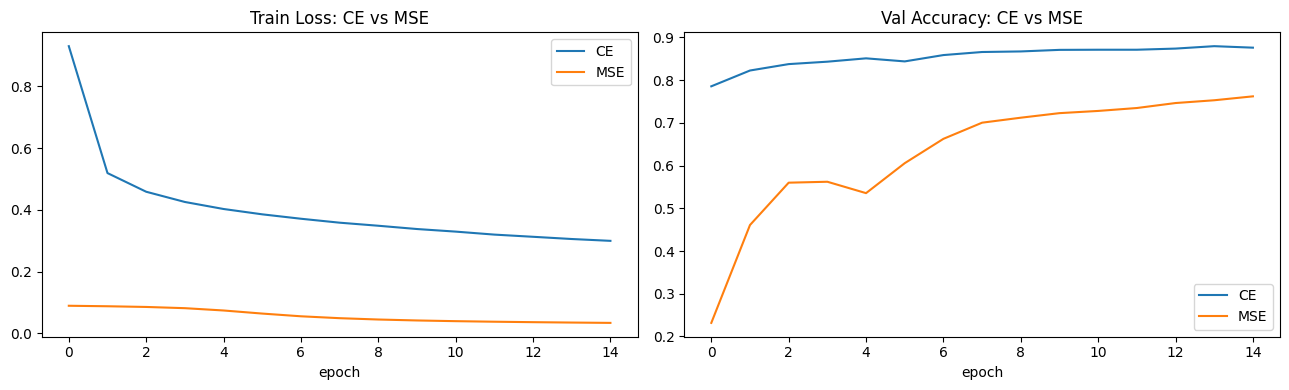

CE  : last train_loss 0.2995 | val_acc 0.8762 | best_val_acc 0.8797
MSE : last train_loss 0.0339 | val_acc 0.7622 | best_val_acc 0.7622


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist_ce["train_loss"], label="CE")
ax[0].plot(hist_mse["train_loss"], label="MSE")
ax[0].set_title("Train Loss: CE vs MSE"); ax[0].legend(); ax[0].set_xlabel("epoch")
ax[1].plot(hist_ce["val_acc"], label="CE")
ax[1].plot(hist_mse["val_acc"], label="MSE")
ax[1].set_title("Val Accuracy: CE vs MSE"); ax[1].legend(); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

print("CE  : last train_loss", round(hist_ce["train_loss"][-1], 4),
      "| val_acc", round(hist_ce["val_acc"][-1], 4),
      "| best_val_acc", round(max(hist_ce["val_acc"]), 4))
print("MSE : last train_loss", round(hist_mse["train_loss"][-1], 4),
      "| val_acc", round(hist_mse["val_acc"][-1], 4),
      "| best_val_acc", round(max(hist_mse["val_acc"]), 4))

## Шаг 4. Сравнение оптимизаторов
SGD(no momentum), SGD+momentum(0.9), Adam(1e-3), AdamW(1e-3, wd=1e-4).
Одинаковая архитектура, 30 эпох.

In [13]:
def run_experiment(name, opt_cls, opt_kwargs, model_kwargs, epochs=30, patience=7):
    torch.manual_seed(42)
    m = MLP(**model_kwargs).to(device)
    o = opt_cls(m.parameters(), **opt_kwargs)
    t0 = time.time()
    h = fit(m, train_loader, val_loader, criterion, o,
            epochs=epochs, patience=patience, verbose=False)
    dt = time.time() - t0
    _, test_acc, _, _ = evaluate(m, test_loader, criterion, device)
    print(f"{name:20s} | best val {max(h['val_acc']):.4f} | test {test_acc:.4f} | {dt:.1f}s")
    return h, test_acc, dt

In [14]:
experiments = [
    ("SGD no momentum", optim.SGD,   {"lr": 0.01},                       {}),
    ("SGD + momentum",  optim.SGD,   {"lr": 0.01, "momentum": 0.9},      {}),
    ("Adam",            optim.Adam,  {"lr": 1e-3},                       {}),
    ("AdamW",           optim.AdamW, {"lr": 1e-3, "weight_decay": 1e-4}, {}),
]

results = {}
for name, cls, kw, mk in experiments:
    results[name] = run_experiment(name, cls, kw, mk, epochs=30)

SGD no momentum      | best val 0.8932 | test 0.8845 | 441.2s
Early stop на эпохе 14
SGD + momentum       | best val 0.8913 | test 0.8855 | 214.0s
Early stop на эпохе 14
Adam                 | best val 0.8985 | test 0.8850 | 223.7s
Early stop на эпохе 16
AdamW                | best val 0.8973 | test 0.8870 | 255.1s


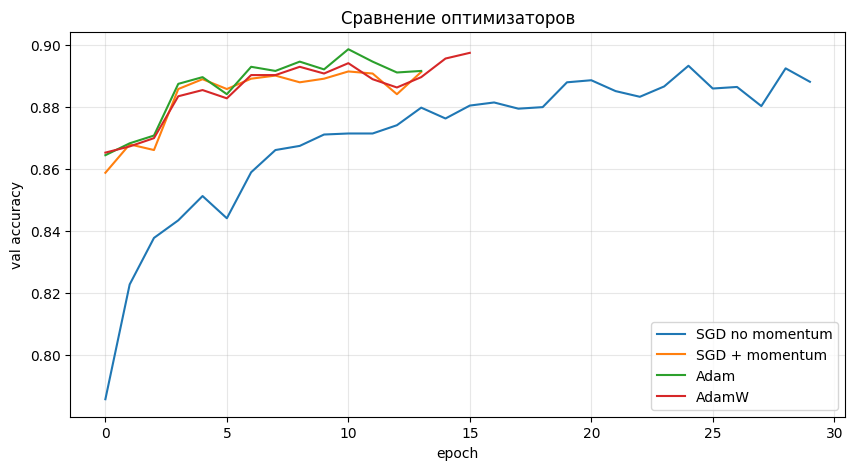

In [15]:
plt.figure(figsize=(10, 5))
for name, (h, _, _) in results.items():
    plt.plot(h["val_acc"], label=name)
plt.xlabel("epoch"); plt.ylabel("val accuracy")
plt.title("Сравнение оптимизаторов"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Шаг 5. Влияние Dropout и BatchNorm
Фиксируем лучший оптимизатор. Три конфигурации:
1) Baseline (без регуляризации)
2) Dropout 0.3
3) Dropout 0.3 + BatchNorm

In [16]:
best_name = "AdamW"   # ← замени, если у тебя лучший другой
opt_map = {
    "SGD no momentum": (optim.SGD,   {"lr": 0.01}),
    "SGD + momentum":  (optim.SGD,   {"lr": 0.01, "momentum": 0.9}),
    "Adam":            (optim.Adam,  {"lr": 1e-3}),
    "AdamW":           (optim.AdamW, {"lr": 1e-3, "weight_decay": 1e-4}),
}
opt_cls, opt_kw = opt_map[best_name]

reg_exps = [
    ("Baseline",     {"dropout_rate": 0.0, "use_batchnorm": False}),
    ("Dropout 0.3",  {"dropout_rate": 0.3, "use_batchnorm": False}),
    ("Dropout + BN", {"dropout_rate": 0.3, "use_batchnorm": True}),
]

reg_results = {}
for name, mk in reg_exps:
    reg_results[name] = run_experiment(name, opt_cls, opt_kw, mk, epochs=30)

Early stop на эпохе 16
Baseline             | best val 0.8973 | test 0.8870 | 255.9s
Early stop на эпохе 27
Dropout 0.3          | best val 0.8975 | test 0.8895 | 442.4s
Early stop на эпохе 21
Dropout + BN         | best val 0.9010 | test 0.8942 | 355.0s


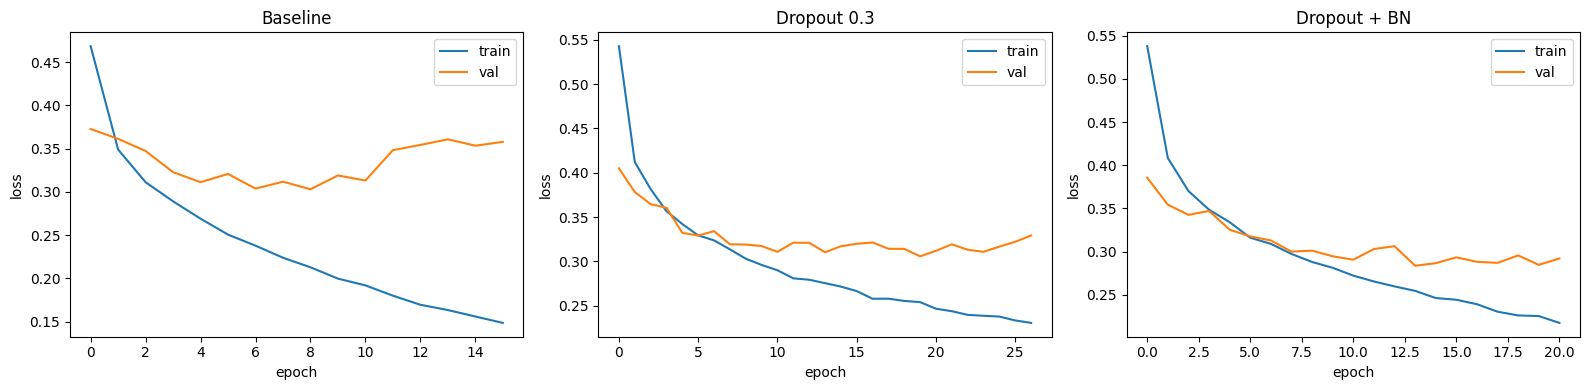

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, (h, _, _)) in zip(axes, reg_results.items()):
    ax.plot(h["train_loss"], label="train")
    ax.plot(h["val_loss"], label="val")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.legend()
plt.tight_layout(); plt.show()

Early stop на эпохе 17
dropout=0.1: test_acc=0.8920
Early stop на эпохе 21
dropout=0.2: test_acc=0.8949
Early stop на эпохе 21
dropout=0.3: test_acc=0.8942
dropout=0.5: test_acc=0.8926


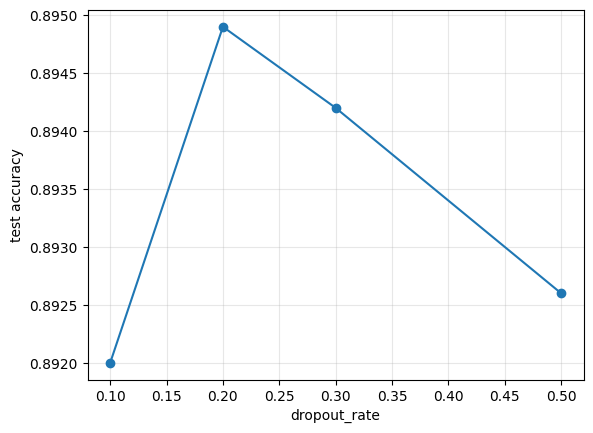

In [18]:
rates = [0.1, 0.2, 0.3, 0.5]
accs = []
for dr in rates:
    torch.manual_seed(42)
    m = MLP(dropout_rate=dr, use_batchnorm=True).to(device)
    o = optim.AdamW(m.parameters(), lr=1e-3, weight_decay=1e-4)
    fit(m, train_loader, val_loader, criterion, o, epochs=30, patience=7, verbose=False)
    _, acc, _, _ = evaluate(m, test_loader, criterion, device)
    accs.append(acc)
    print(f"dropout={dr}: test_acc={acc:.4f}")

plt.plot(rates, accs, marker="o")
plt.xlabel("dropout_rate"); plt.ylabel("test accuracy"); plt.grid(alpha=0.3)
plt.show()

## Шаг 6. Лучшая модель на тесте
Архитектура: MLP + Dropout 0.3 + BatchNorm
Оптимизатор: AdamW(lr=1e-3, wd=1e-4), 40 эпох
Метрики: accuracy, precision, recall, F1 (macro), confusion matrix

In [19]:
torch.manual_seed(42)
best_model = MLP(dropout_rate=0.3, use_batchnorm=True).to(device)
best_opt = optim.AdamW(best_model.parameters(), lr=1e-3, weight_decay=1e-4)

history_best = fit(best_model, train_loader, val_loader, criterion,
                   best_opt, epochs=40, patience=7)

Epoch   1 | 18.0s | Train 0.5379/0.8144 | Val 0.3855/0.8573
Epoch   2 | 18.0s | Train 0.4084/0.8526 | Val 0.3544/0.8668
Epoch   3 | 19.6s | Train 0.3701/0.8656 | Val 0.3426/0.8715
Epoch   4 | 18.1s | Train 0.3485/0.8732 | Val 0.3471/0.8735
Epoch   5 | 18.8s | Train 0.3341/0.8778 | Val 0.3254/0.8823
Epoch   6 | 19.4s | Train 0.3161/0.8835 | Val 0.3176/0.8842
Epoch   7 | 18.5s | Train 0.3090/0.8871 | Val 0.3129/0.8853
Epoch   8 | 19.7s | Train 0.2973/0.8883 | Val 0.3000/0.8862
Epoch   9 | 18.3s | Train 0.2880/0.8931 | Val 0.3011/0.8858
Epoch  10 | 18.5s | Train 0.2813/0.8949 | Val 0.2946/0.8917
Epoch  11 | 19.0s | Train 0.2722/0.8988 | Val 0.2906/0.8918
Epoch  12 | 18.3s | Train 0.2654/0.9003 | Val 0.3030/0.8908
Epoch  13 | 19.7s | Train 0.2597/0.9033 | Val 0.3063/0.8873
Epoch  14 | 18.8s | Train 0.2545/0.9054 | Val 0.2836/0.8953
Epoch  15 | 18.4s | Train 0.2462/0.9092 | Val 0.2866/0.8938
Epoch  16 | 20.9s | Train 0.2443/0.9084 | Val 0.2933/0.8943
Epoch  17 | 18.3s | Train 0.2391/0.9113 

In [20]:
test_loss, test_acc, y_pred, y_true = evaluate(
    best_model, test_loader, criterion, device
)
print(f"Test Accuracy : {test_acc:.4f}")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Precision macro: {precision_score(y_true, y_pred, average='macro'):.4f}")
print(f"Recall macro   : {recall_score(y_true, y_pred, average='macro'):.4f}")
print(f"F1 macro       : {f1_score(y_true, y_pred, average='macro'):.4f}")

Test Accuracy : 0.8942
Test Loss     : 0.3020
Precision macro: 0.8947
Recall macro   : 0.8942
F1 macro       : 0.8943


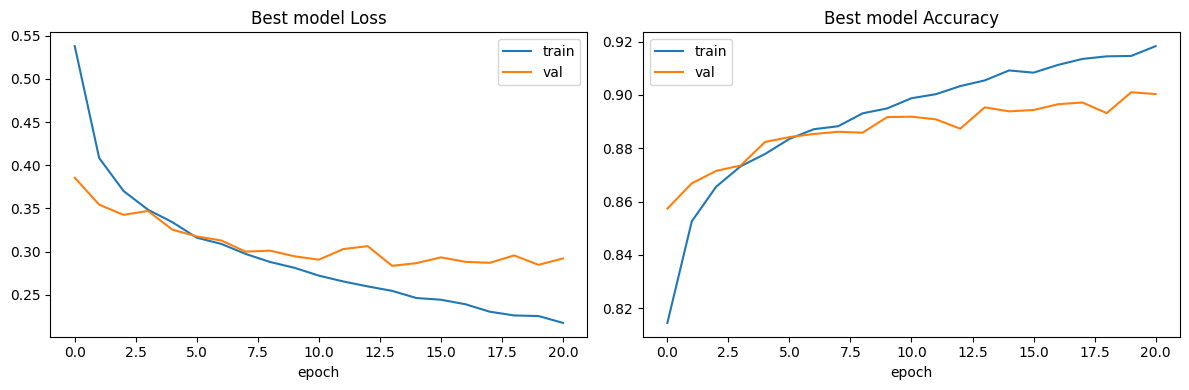

In [21]:
plot_history(history_best, "Best model")

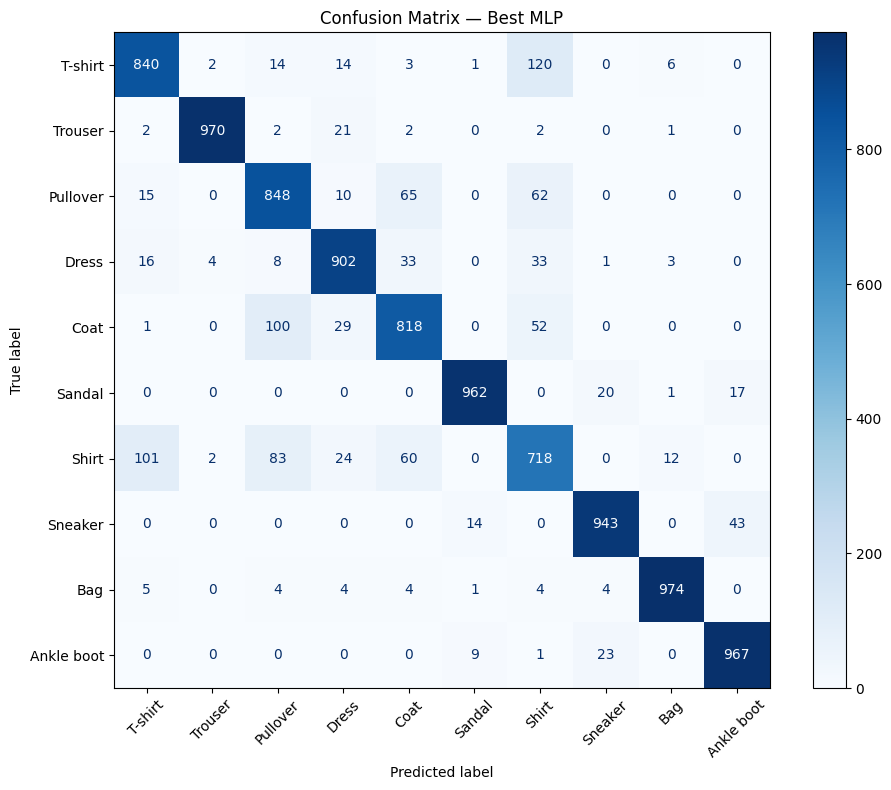

In [22]:
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASSES)
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix — Best MLP")
plt.tight_layout(); plt.show()

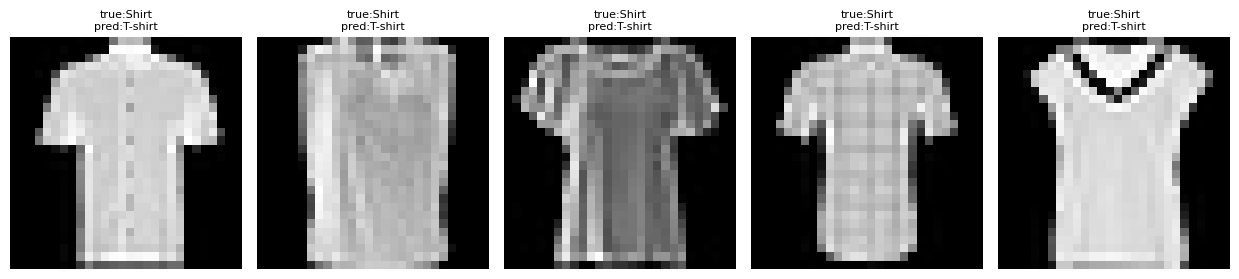

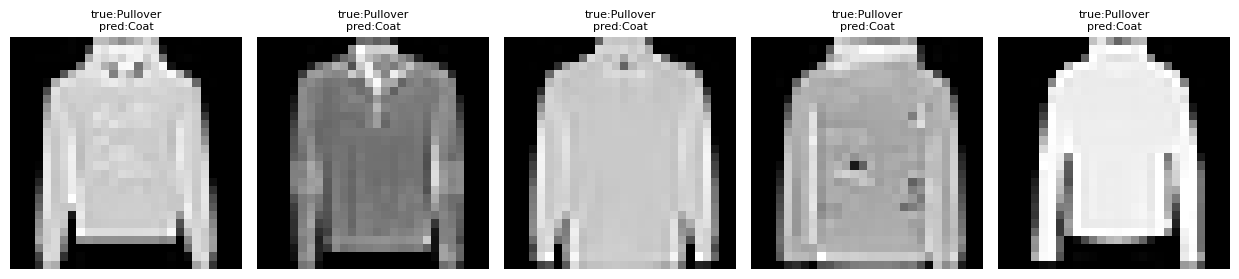

In [23]:
def show_errors(a, b, n=5):
    idx = np.where((y_true == a) & (y_pred == b))[0][:n]
    if len(idx) == 0:
        print(f"Нет ошибок между {CLASSES[a]} и {CLASSES[b]}")
        return
    fig, axes = plt.subplots(1, len(idx), figsize=(2.5*len(idx), 3))
    if len(idx) == 1: axes = [axes]
    for ax, i in zip(axes, idx):
        img, _ = test_dataset[i]
        ax.imshow(img.squeeze(), cmap="gray")
        ax.set_title(f"true:{CLASSES[y_true[i]]}\npred:{CLASSES[y_pred[i]]}", fontsize=8)
        ax.axis("off")
    plt.tight_layout(); plt.show()

show_errors(6, 0)   # Shirt → T-shirt
show_errors(2, 4)   # Pullover → Coat

## Бонус. Логирование метрик в CSV
Модифицируем fit(), добавив запись в training_log.csv.

Early stop на 21


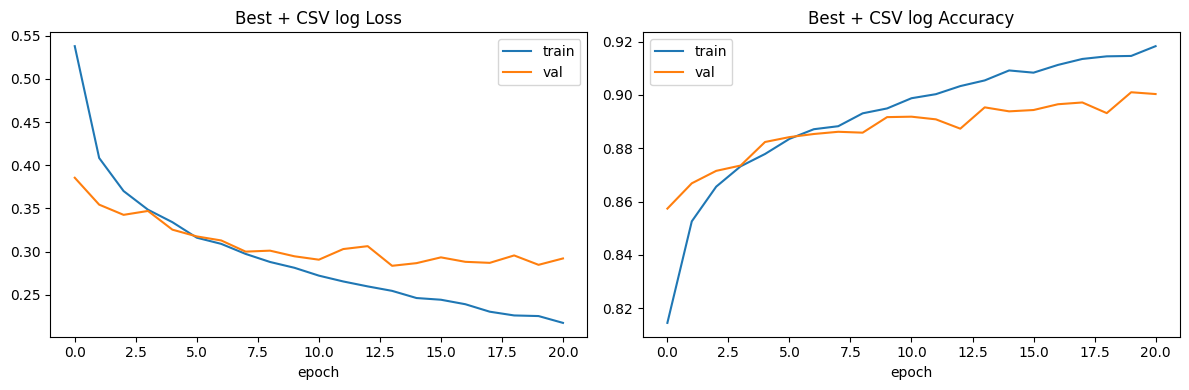

In [24]:
import csv

def fit_with_logging(model, train_loader, val_loader, criterion, optimizer,
                     epochs=30, patience=7, device=device,
                     log_file="training_log.csv"):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val = float("inf"); best_w = deepcopy(model.state_dict()); no_imp = 0
    with open(log_file, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["epoch", "train_loss", "train_acc", "val_loss", "val_acc", "time_sec"])
        for epoch in range(1, epochs+1):
            t0 = time.time()
            tr_loss, tr_acc = train_epoch(model, train_loader, criterion, optimizer, device)
            vl_loss, vl_acc, _, _ = evaluate(model, val_loader, criterion, device)
            dt = time.time()-t0
            history["train_loss"].append(tr_loss); history["val_loss"].append(vl_loss)
            history["train_acc"].append(tr_acc);   history["val_acc"].append(vl_acc)
            w.writerow([epoch, tr_loss, tr_acc, vl_loss, vl_acc, round(dt, 2)])
            if vl_loss < best_val:
                best_val = vl_loss; best_w = deepcopy(model.state_dict()); no_imp = 0
            else:
                no_imp += 1
            if no_imp >= patience:
                print(f"Early stop на {epoch}"); break
    model.load_state_dict(best_w)
    return history

torch.manual_seed(42)
m = MLP(dropout_rate=0.3, use_batchnorm=True).to(device)
o = optim.AdamW(m.parameters(), lr=1e-3, weight_decay=1e-4)
hist_log = fit_with_logging(m, train_loader, val_loader, criterion, o, epochs=40)
plot_history(hist_log, "Best + CSV log")